## Database connectinos and data loader settings

In [1]:
import os, sys, time
os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")
sys.path.insert(0, "/home/albert/Baikal2025")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)

from inference import reader

# Cahching directory
from pathlib import Path
import datetime, json
DATA = Path("data")
DATA.mkdir(exist_ok=True)


CHECKPOINT = ("260816_2250_da_nu_classifier_exp_full_E1_lambda0.01_FIXED_sn256"
              "@best_da_model")

# Домен -> (источник, условия, знаменатель прореживания по частям).
DOMAINS = {
    "exp_full":   ("exp_full",  [reader.NOT_DA_TARGET,
                                 reader.NOT_EXCLUDED], 1),
    "muatm":      ("mc_merged", [reader.NOT_TRAINED,
                                 "e.data_class = 'muatm_2020'"], 10),
    "nuatm":      ("mc_merged", [reader.NOT_TRAINED,
                                 "e.data_class = 'nuatm_2020'"], 10),
    "nue2":       ("mc_merged", [reader.NOT_TRAINED,
                                 "e.data_class = 'nue2_2020'"], 10),
}
COLOURS = {"exp_full": "#d62728", "muatm": "#1f77b4",
           "nuatm": "#2ca02c", "nue2": "#ff7f0e"}

# Порог «яркого» хита. Заряд -- единственная величина в событии, которую не трогала
# ни одна обученная модель, поэтому счётчик ярких хитов служит опорой, независимой
# от sig-noise сети.
BRIGHT_CHARGE_PE = 5.0


def selection(name, thinned=True):
    """Условия отбора домена; при `thinned` — с прореживанием по частям."""
    source, conditions, modulus = DOMAINS[name]
    conditions = list(conditions)
    if thinned and modulus > 1:
        # hash() в DuckDB детерминирован между процессами — проверено, — так что
        # это воспроизводимая выборка частей, а не случайная при каждом запуске.
        conditions.append(f"hash(l.part_key) % {modulus} = 0")
    return source, conditions

## Data loading procedure

In [2]:
from tqdm.auto import tqdm


def streaming(r: reader, where, **kwargs):
    """Чанки читалки с полоской прогресса.

    Читалка сама ничего не печатает -- она библиотека, и печать из неё портила бы
    логи и тесты. Вместо этого она зовёт `progress(...)` с описанием состояния, а
    что с ним делать, решает вызывающий. Здесь -- tqdm.

    `count()` даёт итог заранее, чтобы полоска была полоской, а не спиннером.
    Оговорка: маски (`whole_events`) в SQL не выражаются, поэтому при них реально
    прочитанных событий будет меньше, чем обещал `count()`, и полоска не дойдёт до
    конца. Для mc_reco это около 12 %.
    """
    total = r.count(where=where)
    labels = {"querying": "запрос", "training": "таблица обучения",
              "done": "готово"}
    with tqdm(total=total["events"], unit=" соб", leave=True) as pbar:
        def report(state):
            pbar.set_description(labels.get(
                state.stage, f"часть {state.parts}/{total['parts']}"))
            if state.events:
                pbar.n = state.events
            pbar.refresh()
        yield from r.stream(where=where, progress=report, **kwargs)


def per_event_features(chunk):
    """Свойства события, посчитанные из его хитов. Сами хиты никуда не сохраняются.

    Нужны две группировки: по всем хитам и только по ярким. У события может не быть
    ни одного яркого хита, поэтому вторая покрывает не все события, и недостающие
    строки восстанавливаются через reindex -- иначе счётчики съедут относительно
    chunk.events на молчаливую величину.
    """
    hits = chunk.hits
    positions = range(len(chunk.events))
    all_hits = hits.groupby("event")
    bright = hits[hits.q > BRIGHT_CHARGE_PE].groupby("event")

    def counted(grouped, value=0):
        return grouped.reindex(positions, fill_value=value).to_numpy()

    def span(grouped, column):
        return (grouped[column].max() - grouped[column].min()).reindex(positions).to_numpy()

    return pd.DataFrame({
        "n_hits":                 counted(all_hits.size()),
        "n_bright_hits":          counted(bright.size()),
        "n_signal_hits":          counted(all_hits["is_sig"].sum()),
        "n_strings":              counted(all_hits["string"].nunique()),
        "n_strings_with_bright":  counted(bright["string"].nunique()),
        "charge_total_pe":        counted(all_hits["q"].sum(), 0.0),
        "charge_in_bright_pe":    counted(bright["q"].sum(), 0.0),
        "brightest_hit_pe":       counted(bright["q"].max(), np.nan),
        "time_span_ns":           span(all_hits, "t"),
        "time_span_of_bright_ns": span(bright, "t"),
        "z_span_of_bright_m":     span(bright, "z"),
    }, index=positions)


def signal_hit_geometry(chunk):
    """Наклон z(t), его ошибка и разбросы -- по сигнальным хитам, в двух взвешиваниях.

    Всё считается замкнутыми формулами МНК из шести сумм, каждая -- один bincount.
    Ни цикла по событиям, ни groupby: 636 тыс. событий в секунду, то есть около 0.1 %
    от стоимости чтения чанка, ради которого хиты и поднимаются с диска.

    Наклон в м/нс, так что сравнивать его есть с чем: вертикальный релятивистский
    трек даёт |dz/dt| = 0.2998.

    Вес `q` -- не обратная дисперсия, поэтому взвешенная "ошибка наклона" это не
    статистическая ошибка в строгом смысле, а разброс с оглядкой на яркость хитов.
    Колонки с суффиксом `_q` -- взвешенные, без суффикса -- нет.

    `sigma_horizontal` = sqrt(var x + var y) тождественно равна СКО расстояния от
    центроида в плоскости, так что второй вариант -- `sigma_radius`, разброс
    расстояния до оси кластера. Отношения не считаются: их дешевле взять ниже по
    анализу, чем тащить лишнюю колонку через все домены.
    """
    hits = chunk.hits
    signal = hits["is_sig"].to_numpy()
    n_events = len(chunk.events)
    event = hits["event"].to_numpy()[signal]
    t = hits["t"].to_numpy()[signal].astype(np.float64)
    z = hits["z"].to_numpy()[signal].astype(np.float64)
    x = hits["x"].to_numpy()[signal].astype(np.float64)
    y = hits["y"].to_numpy()[signal].astype(np.float64)
    q = hits["q"].to_numpy()[signal].astype(np.float64)
    r = np.hypot(x, y)
    counted = np.bincount(event, minlength=n_events)

    columns = {}
    for tag, w in (("", np.ones(len(event))), ("_q", q)):
        total = lambda v: np.bincount(event, weights=w * v, minlength=n_events)
        Sw = np.bincount(event, weights=w, minlength=n_events)
        St, Sz, Stt, Szz, Stz = total(t), total(z), total(t * t), total(z * z), total(t * z)
        Sx, Sy, Sxx, Syy = total(x), total(y), total(x * x), total(y * y)
        Sr, Srr = total(r), total(r * r)

        with np.errstate(divide="ignore", invalid="ignore"):
            denominator = Sw * Stt - St * St
            # Меньше трёх хитов -- прямая проходит точно, разброс не определён.
            # Нулевой знаменатель -- все хиты в один момент времени.
            usable = (counted >= 3) & (denominator > 0) & (Sw > 0)
            slope = np.where(usable, (Sw * Stz - St * Sz) / denominator, np.nan)
            intercept = np.where(usable, (Stt * Sz - St * Stz) / denominator, np.nan)
            residual = np.clip(Szz - intercept * Sz - slope * Stz, 0.0, None)
            spread = np.where(usable, np.sqrt(residual / Sw), np.nan)
            error = np.where(usable,
                             np.sqrt(residual / np.maximum(counted - 2, 1) * Sw / denominator),
                             np.nan)
            centred = lambda first, second: np.clip(second / Sw - (first / Sw) ** 2, 0.0, None)
            sigma_z = np.where(Sw > 0, np.sqrt(centred(Sz, Szz)), np.nan)
            sigma_horizontal = np.where(Sw > 0,
                                        np.sqrt(centred(Sx, Sxx) + centred(Sy, Syy)), np.nan)
            sigma_radius = np.where(Sw > 0, np.sqrt(centred(Sr, Srr)), np.nan)

        columns.update({
            f"z_t_slope_m_per_ns{tag}":       slope,
            f"z_t_slope_error_m_per_ns{tag}": error,
            f"z_t_residual_rms_m{tag}":       spread,
            f"sigma_z_m{tag}":                sigma_z,
            f"sigma_horizontal_m{tag}":       sigma_horizontal,
            f"sigma_radius_m{tag}":           sigma_radius,
        })
    return pd.DataFrame({name: values.astype(np.float32)
                         for name, values in columns.items()})


def load(name, budget_mb=512):
    """События домена с признаками из хитов. Хиты не возвращаются.

    Читаются они всё равно -- ни числа хитов, ни яркости без них не получить, -- но
    живут только внутри чанка. Прежняя версия копила их в общий фрейм, а дальше по
    ноутбуку использовались одни счётчики; для exp_full это десятки гигабайт впустую.

    `n_signal_hits` считается здесь заново и обязан совпасть с `n_sn_hits` из базы:
    их писали разные проходы по одним и тем же вероятностям, так что расхождение
    означало бы сбой адресации. `verify` проверяет ровно это на каждом чанке.
    """
    source, conditions = selection(name)
    r = reader.open(source, checkpoint=CHECKPOINT)
    t0 = time.time()
    frames, read = [], 0
    for chunk in streaming(r, conditions, budget_mb=budget_mb):
        r.verify(chunk)                      # сверка адресации на каждом чанке
        events = chunk.events.reset_index(drop=True)
        # Логит, а не сам скор: сеть бинарная, так что это преактивация сигмоиды.
        # Насыщения нет -- по обеим базам скор лежит в [1.6e-4, 0.9964], ни одного
        # ровно нуля или единицы, -- поэтому log(p/(1-p)) из сохранённого float32
        # точен до ~2e-5 по логиту, и гонять модель заново незачем.
        events["logit"] = np.log(events["score"] / (1.0 - events["score"]))
        frames.append(pd.concat([events, per_event_features(chunk),
                                 signal_hit_geometry(chunk),
                                 ], 
                                 axis=1))
        read += chunk.meta.get("hits_read", 0)
    ev = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    return ev, dict(домен=name, событий=len(ev), хитов_прочитано=read,
                    частей=ev.part_key.nunique() if len(ev) else 0,
                    память_МБ=round(ev.memory_usage(deep=True).sum() / 1e6, 1),
                    секунд=round(time.time() - t0, 1))

# ============== Caching the loaded data to avoid reloading every time =================
def cache_fingerprint(name, frame=None):
    """Чем определяется содержимое кеша: чекпоинт, условия отбора, набор колонок.

    Если что-то из этого поменялось, старый файл описывает уже другие данные. Молча
    подсунутый устаревший кеш -- ошибка, которую никакой график не покажет, поэтому
    отпечаток пишется рядом и сверяется при чтении.
    """
    source, conditions = selection(name)
    fingerprint = {"checkpoint": CHECKPOINT, "source": source,
                   "conditions": [str(c) for c in conditions]}
    if frame is not None:
        fingerprint["columns"] = list(frame.columns)
    return fingerprint

def load_cached(name):
    """Кеш этого домена, если он описывает то же, что посчитал бы `load`.

    При расхождении -- исключение, а не тихое чтение: разойтись могут чекпоинт,
    каты или набор колонок, и во всех трёх случаях числа будут выглядеть
    правдоподобно и быть не теми.
    """
    stored = json.loads((DATA / "manifest.json").read_text())[name]
    expected = cache_fingerprint(name)
    differs = [key for key, value in expected.items() if stored.get(key) != value]
    if differs:
        raise RuntimeError(
            f"кеш {name} устарел по полям {differs}: "
            f"было {[stored.get(k) for k in differs]}, стало {[expected[k] for k in differs]}")
    return pd.read_parquet(DATA / f"{name}.parquet")

def load_cahed_fit(name):
    """Кеш фита этого домена, если он описывает то же, что посчитал бы `fit_domain`.

    При расхождении -- исключение, а не тихое чтение: разойтись могут чекпоинт,
    каты или набор колонок, и во всех трёх случаях числа будут выглядеть
    правдоподобно и быть не теми.
    """
    stored = json.loads((DATA / "manifest.json").read_text())[name]
    expected = cache_fingerprint(name)
    differs = [key for key, value in expected.items() if stored.get(key) != value]
    if differs:
        raise RuntimeError(
            f"кеш {name} устарел по полям {differs}: "
            f"было {[stored.get(k) for k in differs]}, стало {[expected[k] for k in differs]}")
    return pd.read_parquet(DATA / f"fit_{name}.parquet")


# ================== Functions to provide reconstruction ==========================
from inference.track_fit_alike_bars import fit_events, masks, tqdm_progress
SCORE_CUT, N_WORKERS = 0.5, 16

def channel_mask_for(source):
    """DQM-маска каналов. У данных она есть (txt-файл рана), у МК её нет по построению."""
    if source != "exp_full":
        return None
    cache = {}

    def provider(rows):
        part = rows["part_key"].iloc[0]
        if part not in cache:
            cache[part] = masks.dqm_masks(source, part)
        return cache[part]

    return provider

def fit_domain(name, score_cut=SCORE_CUT, workers=N_WORKERS):
    ev = EV[name]
    todo = ev.loc[ev["score"] > score_cut,
                  ["source", "data_class", "part_key", "local_idx"]]
    if todo.empty:
        return pd.DataFrame()
    t0 = time.time()
    with tqdm_progress(f"фит {name}") as progress:
        fits = fit_events(todo, n_workers=workers,
                          channel_mask=channel_mask_for(ev["source"].iloc[0]),
                          progress=progress)
    fits = fits.add_prefix("fit_")
    print(f"{name}: {len(todo)} событий за {time.time() - t0:.0f} с, "
          f"сошлось {(fits['fit_status'] == 'ok').mean():.0%}")
    return fits

def with_fit(name):
    """EV[name] + колонки фита; выравнивание по индексу, порядок не меняется."""
    return EV[name].join(FIT[name]) if name in FIT else EV[name]

In [3]:
# =================== Try load cache first, if not available, load from source and cache it =========================
try:
    #raise FileNotFoundError("Forced reload from source")
    EV = {name: load_cached(name) for name in DOMAINS}
    FIT = {name: load_cahed_fit(name) for name in ['exp_full', 'muatm']}

except FileNotFoundError or RuntimeError as e:
    print("No cache found, loading from source... Reason:", e)
    # Load df from source
    EV, report = {}, []
    for name in DOMAINS:
        EV[name], info = load(name)
        report.append(info)
    display(pd.DataFrame(report))
    # Apply fit to the loaded data
    FIT = {name: fit_domain(name) for name in ['exp_full', 'muatm']}

    # Create df cache
    manifest = {name: {**cache_fingerprint(name, frame), "events": len(frame),
                    "written": datetime.datetime.now().isoformat(timespec="seconds")}
                for name, frame in EV.items()}
    for name, frame in EV.items():
        frame.reset_index(drop=True).to_parquet(DATA / f"{name}.parquet", index=False)
    (DATA / "manifest.json").write_text(json.dumps(manifest, indent=2, ensure_ascii=False))
    display(pd.DataFrame({name: {"событий": entry["events"],
                        "колонок": len(entry["columns"]),
                        "МБ": round((DATA / f"{name}.parquet").stat().st_size / 1e6, 1)}
                for name, entry in manifest.items()}))

    for name, fr in FIT.items():                  # посчитали один раз — сохранили
        if len(fr):
            fr.to_parquet(DATA / f"fit_{name}.parquet")
    

In [4]:
EV['exp_full'][EV['exp_full']['score'] > 0.7]['part_key'].value_counts().sort_index()

part_key
part_s2020_c02_r0055     322
part_s2020_c02_r0104     169
part_s2020_c03_r0018     312
part_s2020_c03_r0254     240
part_s2020_c03_r0348     152
part_s2020_c03_r0445       5
part_s2020_c04_r0031     437
part_s2020_c04_r0057      92
part_s2020_c04_r0080     479
part_s2020_c04_r0108     525
part_s2020_c04_r0130     135
part_s2020_c05_r0022    1870
part_s2020_c05_r0261     234
part_s2020_c05_r0337      71
part_s2020_c05_r0396      79
part_s2020_c06_r0024     389
part_s2020_c06_r0152     216
part_s2020_c06_r0274     246
part_s2020_c06_r0388     223
part_s2020_c06_r0481      82
part_s2020_c07_r0016    1699
part_s2020_c07_r0133     322
part_s2020_c07_r0255      96
part_s2020_c07_r0354     130
part_s2020_c07_r0465      83
Name: count, dtype: int64

In [5]:



# FIT = {name: fit_domain(name) for name in ['exp_full', 'muatm']}

# for name, fr in FIT.items():                  # посчитали один раз — сохранили
#     if len(fr):
#         fr.to_parquet(DATA / f"fit_{name}.parquet")

# def with_fit(name):
#     """EV[name] + колонки фита; выравнивание по индексу, порядок не меняется."""
#     return EV[name].join(FIT[name]) if name in FIT else EV[name]


In [6]:
for name in EV:
    EV[name]['z_verticality_1'] = (EV[name]['sigma_z_m'] / EV[name]['sigma_horizontal_m']).replace([np.inf, -np.inf], np.nan)
    EV[name]['z_verticality_2'] = (EV[name]['sigma_z_m_q'] / EV[name]['sigma_horizontal_m_q']).replace([np.inf, -np.inf], np.nan)
    EV[name]['z_verticality_3'] = (EV[name]['sigma_z_m'] / EV[name]['sigma_radius_m']).replace([np.inf, -np.inf], np.nan)
    EV[name]['z_verticality_4'] = (EV[name]['sigma_z_m_q'] / EV[name]['sigma_radius_m_q']).replace([np.inf, -np.inf], np.nan)
    EV[name]['score_zt_baseline'] = 1/(1+np.exp(-EV[name]['z_t_slope_m_per_ns']))
muatm = EV['muatm'].join(FIT['muatm'])
exp = EV['exp_full'].join(FIT['exp_full'])
nuatm = EV['nuatm']#.join(FIT['nuatm'])
nue2 = EV['nue2']#.join(FIT['nue2'])
hist_kwargs = dict(density=True, bins=50, alpha=0.5, histtype='step')

## Different plots

In [ ]:
def _apply_mask(df: pd.DataFrame):
    mask = df.n_sn_hits>=8
    mask &= df.n_sn_strings>=3
    if 'fit_status' in df.columns:
        mask &= df.fit_status == 'ok'
    return df[mask].copy()

muatm_masked = _apply_mask(muatm)
exp_masked = _apply_mask(exp)
nue2_masked = _apply_mask(nue2)
nuatm_masked = _apply_mask(nuatm)

for col_to_plot, range_tuple in [
    ("z_verticality_1", (0, 3)), 
    ("z_t_slope_m_per_ns", None),
    ("z_t_slope_error_m_per_ns", None),
    ("z_t_slope_m_per_ns_q", None),
    ("z_t_residual_rms_m", None),
    ("z_t_residual_rms_m_q", None),
    ("sigma_z_m", (0, 50)),
    ("sigma_z_m_q", (0, 50)),
    ]:
    _hist_kwargs = dict(density=True, bins=50, alpha=0.5, histtype='step', log=True, range=range_tuple)
    plt.hist(muatm_masked[col_to_plot].clip(*range_tuple) if range_tuple else muatm_masked[col_to_plot], label=f"muatm, total={len(muatm_masked)}", **_hist_kwargs)
    plt.hist(exp_masked[col_to_plot].clip(*range_tuple) if range_tuple else exp_masked[col_to_plot], label=f"exp, total={len(exp_masked)}", **_hist_kwargs)
    plt.hist(nue2_masked[col_to_plot].clip(*range_tuple) if range_tuple else nue2_masked[col_to_plot], label=f"nue2, total={len(nue2_masked)}", ls='--', **_hist_kwargs)
    plt.xlabel(col_to_plot)
    plt.ylabel("Density")
    plt.legend()
    plt.grid(ls=":")
    plt.show()

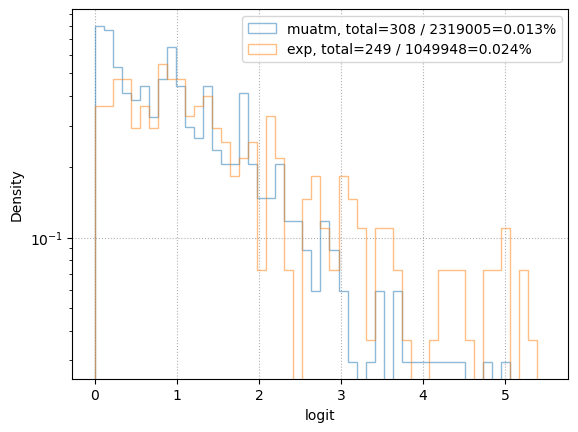

In [38]:
def hitsstrings_mask(df: pd.DataFrame):
    mask = (df.n_sn_hits>=8)
    mask &= (df.n_sn_strings>=3)
    return mask

def _apply_mask(df: pd.DataFrame):
    #mask = (df.z_t_slope_m_per_ns_q >= 0.0)
    #mask &= (df.logit>=4)
    #mask = (df.sigma_z_m >= 50)
    #mask &= (df.z_verticality_1 <= 4000)
    #mask &= (df.z_t_residual_rms_m_q <= 15)
    #mask &= (df.z_t_slope_error_m_per_ns_q <= 0.1)
    #mask &= (df.n_hits < 80)
    #mask &= (df.n_hits >= 50) & (df.n_hits <= 100)
    #mask = (df.n_sn_hits>=8)
    #mask &= (df.n_sn_strings>=3)
    mask = (df.score>=0.5)
    mask &= (df.n_sn_hits>=8)
    mask &= (df.n_sn_strings>=3)


    mask &= (df.fit_n_hits>=8)
    mask &= (df.fit_n_strings>=3)
    mask &= (df.fit_status == 'ok')
    mask &= (df.fit_cov_matrix_status == 3)
    
    
    mask &= (df.fit_z_dist > 70)
    # mask &= (df.fit_scf_max_theta < 1.7)
    mask &= (np.log10(df["fit_time_chi2"] / (df.fit_n_hits - 5)) < 1.0)

    mask &= ((df["fit_n_triplets"] / (df.fit_n_hits - 5)) > 0.1)
    mask &= ((df["fit_q_acc_20"] / df["fit_q_tot_20"]) > 0.05)
    mask &= (df.fit_t_res_30_med < 60)
    mask &= (df["fit_log_phit_30_min"] > -9)
    mask &= (df.fit_theta_err <= 2.5)

    mask &= (df["fit_ev_center_z"] < 220)
    mask &= (df.fit_theta_rec <= 80)

    return df[mask].copy()


col_to_plot = "logit"
_hist_kwargs = dict(density=True, bins=50, alpha=0.5, histtype='step', log=True, range=(0, 5.5))
plt.hist(_apply_mask(muatm)[col_to_plot], label=f"muatm, total={len(_apply_mask(muatm))} / {sum(hitsstrings_mask(muatm))}={len(_apply_mask(muatm))/sum(hitsstrings_mask(muatm))*100 if sum(hitsstrings_mask(muatm)) > 0 else 0:.3f}%", **_hist_kwargs)
plt.hist(_apply_mask(exp)[col_to_plot], label=f"exp, total={len(_apply_mask(exp))} / {sum(hitsstrings_mask(exp))}={len(_apply_mask(exp))/sum(hitsstrings_mask(exp))*100 if sum(hitsstrings_mask(exp)) > 0 else 0:.3f}%", **_hist_kwargs)
#plt.hist(_apply_mask(nue2)[col_to_plot], label=f"nue2, total={len(_apply_mask(nue2))} / {sum(hitsstrings_mask(nue2))}={len(_apply_mask(nue2))/sum(hitsstrings_mask(nue2))*100 if sum(hitsstrings_mask(nue2)) > 0 else 0:.3f}%", ls='--', **_hist_kwargs)
#plt.hist(_apply_mask(nuatm)[col_to_plot], label=f"nuatm, total={len(_apply_mask(nuatm))} / {sum(hitsstrings_mask(nuatm))}={len(_apply_mask(nuatm))/sum(hitsstrings_mask(nuatm))*100 if sum(hitsstrings_mask(nuatm)) > 0 else 0:.3f}%", ls='--', **_hist_kwargs)
plt.xlabel(col_to_plot)
plt.ylabel("Density")
plt.legend()
plt.grid(ls=":")
plt.show()

In [9]:
# np.log10(muatm['fit_time_chi2']/ (muatm.fit_n_hits - 5)).hist(bins=50, alpha=0.5, histtype='step', density=True, range=(-1, 2))
# np.log10(exp['fit_time_chi2']/ (exp.fit_n_hits - 5)).hist(bins=50, alpha=0.5, histtype='step', density=True, range=(-1, 2))
# plt.show()

# muatm['fit_z_dist'].hist(bins=50, alpha=0.5, histtype='step', density=True, range=(0, 200))
# exp['fit_z_dist'].hist(bins=50, alpha=0.5, histtype='step', density=True, range=(0, 200))

In [10]:
# muatm_residual = _apply_mask(muatm)
# (muatm_residual['prime_theta_deg'] - muatm_residual['fit_theta_rec']).hist(bins=50, alpha=0.5, histtype='step')
# muatm_residual['fit_theta_err'].hist(bins=50, alpha=0.5, histtype='step')

## Observe distinct events

#### Helper functions

In [18]:
import h5py


#: Что лежит в `raw/labels` -- смысл у источников РАЗНЫЙ, и это ловушка:
#:   mc_merged, mc_reco -- правда: код происхождения импульса (fMagic).
#:       0 -- шум, отрицательные -- свет мюонного трека, k*10**6 + j -- свет ливня k;
#:   exp_reco -- маска scanfit (0/1), то есть реконструкция BARS, а не правда;
#:   exp_full -- нули: у данных правды нет.
#: Поэтому `truth=True` для данных не «нарисует что-нибудь похожее», а упадёт.
LABELS_MEANING = {"mc_merged": "правда", "mc_reco": "правда",
                  "exp_reco": "маска scanfit", "exp_full": "ничего (нули)",
                  "exp": "ничего (нули)"}


def attach_hits(events, threshold=reader.SN_THRESHOLD, fits=None, truth=False):
    """Хиты выбранных событий -- по колонке-списку на величину.

    Рассчитано на горсть событий: читает срез `raw/data[start:end]` на каждое, а не
    пачками, как `reader.stream`. Для семи строк это правильный размен -- ридер
    оптимизирован под тысячи событий и сливает соседние в общие пролёты.

    Ждёт колонки `source`, `part_key`, `local_idx` и, для MC, `data_class` -- ровно то,
    что кладёт в кадр читалка. Индекс входного кадра сохраняется.

    `is_sig` берётся из того же файла вероятностей и тем же строгим `>` во float32,
    что и везде в пайплайне: с `>=` одно событие из двадцати тысяч получило бы другое
    число сигнальных хитов, чем записано в базе предсказаний.

    `fits` -- кадр от `fit_events(..., keep_objects=True)` для этих же событий, с тем
    же индексом; можно не передавать, если колонка `fit` с объектами `TrackFit` уже
    лежит в кадре. Тогда добавляется `is_fit` -- импульсы, взятые в трек реконструкцией.
    Порядок импульсов совпадает с этим чтением по построению: и `read_event_hits`,
    откуда фит берёт хиты, и этот срез режут один и тот же `raw/data[start:stop]`,
    поэтому `fit_hits` индексируют ровно эти массивы. Несшиеся события дают нули.

    `truth=True` -- только для МК-источников (`mc_merged`, `mc_reco`) -- добавляет три
    колонки по `raw/labels`: `is_truth` (любой свет, то есть не шум), `is_truth_track`
    (свет мюонного трека) и `is_truth_shower` (свет ливней). Для данных правды не
    существует, и попытка её попросить -- исключение, а не молчаливая подмена: в
    `exp_reco` в том же поле лежит маска scanfit, а в `exp_full` одни нули.
    """
    if fits is None and "fit" in getattr(events, "columns", ()):
        fits = events                      # объекты фита уже в кадре
    wanted = ["q", "t", "x", "y", "z", "channel", "prob", "is_sig"]
    if fits is not None:
        wanted.append("is_fit")
    if truth:
        wanted += ["is_truth", "is_truth_track", "is_truth_shower"]
    collected = {name: [None] * len(events) for name in wanted}
    positions = {key: index for index, key in enumerate(events.index)}

    grouping = ["source", "part_key"] + (["data_class"] if "data_class" in events else [])
    for keys, block in events.groupby(grouping, sort=False):
        keys = keys if isinstance(keys, tuple) else (keys,)
        source, part_key = keys[0], keys[1]
        if truth and LABELS_MEANING.get(source) != "правда":
            raise ValueError(
                f"{source}: в raw/labels не правда, а "
                f"{LABELS_MEANING.get(source, 'неизвестно что')}. Правда есть только "
                f"у mc_merged и mc_reco.")
        group_name = reader.spec.h5_group(source, keys[2]) if len(keys) > 2 else source
        specification = reader.spec.SOURCES[source]

        with h5py.File(specification.h5, "r") as store, \
             h5py.File(specification.probs, "r") as probabilities:
            hits = store[group_name]["raw"]
            boundaries = hits["ev_starts"][part_key]["data"]
            data = hits["data"][part_key]["data"]
            channels = hits["channels"][part_key]["data"]
            labels = hits["labels"][part_key]["data"] if truth else None
            probs = probabilities[group_name]["probs"][part_key]["data"]

            for label, local in zip(block.index, block.local_idx.to_numpy()):
                start, stop = int(boundaries[local]), int(boundaries[local + 1])
                block_of_hits = data[start:stop]
                probability = probs[start:stop]
                slot = positions[label]
                for column, name in enumerate(reader.HIT_VARS):
                    collected[name][slot] = block_of_hits[:, column].tolist()
                collected["channel"][slot] = channels[start:stop].tolist()
                collected["prob"][slot] = probability.tolist()
                collected["is_sig"][slot] = reader.signal_mask(probability, threshold).tolist()

                if truth:
                    code = labels[start:stop]
                    collected["is_truth"][slot] = (code != 0).tolist()
                    collected["is_truth_track"][slot] = (code < 0).tolist()
                    collected["is_truth_shower"][slot] = (code > 0).tolist()

                if fits is not None:
                    in_fit = np.zeros(stop - start, dtype=bool)
                    taken = getattr(fits["fit"].loc[label], "fit_hits", None)
                    if taken is not None and len(taken):
                        index = np.asarray(taken, dtype=np.int64)
                        if index.max() >= in_fit.size:
                            raise ValueError(
                                f"{label}: индекс хита {index.max()} вне события "
                                f"({in_fit.size} импульсов) -- кадр и фит разошлись")
                        in_fit[index] = True
                    collected["is_fit"][slot] = in_fit.tolist()

    return events.assign(**collected)


def draw_event(row, axis=None, selection=None, context=None, show_noise=True,
               true_aspect=True, marker_scale=90):
    """Одно событие в 3D: цвет -- время, размер -- заряд, форма -- чем отобран хит.

    Время как цвет выбрано не для красоты: по нему видно, в какую сторону шёл фронт
    света, а это и есть то, что отличает трек от набора случайных срабатываний.

    Набор задаётся **именем колонки-списка с булевой маской**: `selection="is_fit"` --
    рисовать трек реконструкции, `"is_sig"` -- выбор сети сигнал/шум. Свою маску тоже
    можно положить колонкой в кадр (`frame["is_bright"] = [q > 5 for q in frame.q]`) и
    назвать её здесь -- функция не знает, откуда она взялась. По умолчанию берётся
    `is_fit`, если она есть, иначе `is_sig`.

    `context` -- второй набор для сравнения, рисуется полыми квадратами; по умолчанию,
    когда рисуется трек, это выбор сети (то есть видно, что сеть взяла, а трек -- нет).
    `show_noise` гасит всё остальное, но не выбрасывает: по расположению невыбранных
    хитов видно, был ли у отбора выбор вообще.

    `true_aspect` держит одинаковый масштаб по всем осям. Кластер 120 м в поперечнике
    и сотни метров по глубине, так что честная картинка выходит узкой и высокой. Это
    неудобно, но искажённые пропорции врали бы ровно про то, ради чего событие и
    смотрят -- про наклон трека.
    """
    x = np.asarray(row.x); y = np.asarray(row.y); z = np.asarray(row.z)
    t = np.asarray(row.t); q = np.asarray(row.q)

    def mask_of(name):
        if name not in row.index:
            available = [c for c in row.index if c.startswith("is_")]
            raise KeyError(f"нет колонки {name!r} с маской; в кадре есть {available}")
        return np.asarray(row[name], dtype=bool)

    if selection is None:
        selection = "is_fit" if "is_fit" in row.index else "is_sig"
    selected = mask_of(selection)
    if context is None and selection == "is_fit" and "is_sig" in row.index:
        context = "is_sig"                  # что взяла сеть, но не взял трек
    other = mask_of(context) if context is not None else np.zeros_like(selected)
    rest = ~selected & ~other

    if axis is None:
        axis = plt.figure(figsize=(6, 7)).add_subplot(projection="3d")

    # Струны, задетые в этом событии -- по средней позиции их каналов.
    strings = np.asarray(row.channel) // reader.STRING_DIVISOR
    for string in np.unique(strings):
        on_string = strings == string
        axis.plot([x[on_string].mean()] * 2, [y[on_string].mean()] * 2,
                  [z.min(), z.max()], color="0.85", lw=0.8, zorder=0)

    size = marker_scale * np.sqrt(q / max(q.max(), 1e-9))
    if show_noise and rest.any():
        axis.scatter(x[rest], y[rest], z[rest], s=size[rest] * 0.5, c="0.65",
                     marker="x", alpha=0.35, linewidths=0.6,
                     label=f"остальное, {rest.sum()}")
    
    drawn = axis.scatter(x[selected], y[selected], z[selected], s=size[selected],
                         c=t[selected], cmap="plasma", edgecolors="k", linewidths=0.3,
                         depthshade=False, label=f"{selection}, {selected.sum()}")
    if other.any():
            axis.scatter(x[other], y[other], z[other], s=size[other] * 0.7,
                         facecolors="none", edgecolors="tab:blue", marker="s",
                         linewidths=0.9, label=f"{context}, {other.sum()}")

    if true_aspect:
        extent = max(np.ptp(x), np.ptp(y), np.ptp(z)) or 1.0
        axis.set_box_aspect((np.ptp(x) / extent, np.ptp(y) / extent, np.ptp(z) / extent))

    axis.set(xlabel="x, м", ylabel="y, м", zlabel="z, м")
    described = [f"{name}={row[name]:.3g}" for name in
                 ("score", "logit", "n_sn_hits", "n_sn_strings", "fit_theta_rec",
                  "fit_z_dist", "prime_theta_deg") if name in row]
    axis.set_title(f"{row.part_key} #{row.local_idx}\n" + "  ".join(described), fontsize=8)
    axis.legend(fontsize=7, loc="upper left")
    return axis, drawn


def draw_events(frame, per_row=4, **kwargs):
    """Сетка событийных дисплеев, по одному на строку кадра."""
    rows = int(np.ceil(len(frame) / per_row))
    figure = plt.figure(figsize=(8 * per_row, 8 * rows))
    for number, (_, row) in enumerate(frame.iterrows(), start=1):
        axis = figure.add_subplot(rows, per_row, number, projection="3d")
        _, drawn = draw_event(row, axis=axis, **kwargs)
        figure.colorbar(drawn, ax=axis, shrink=0.55, pad=0.12, label="время, нс")
    figure.tight_layout()
    return figure

#### Select events to plot

In [19]:

def _apply_mask(df: pd.DataFrame):
    #mask = (df.z_t_slope_m_per_ns_q >= 0.0)
    #mask &= (df.logit>=4)
    #mask = (df.sigma_z_m >= 50)
    #mask &= (df.z_verticality_1 <= 4000)
    #mask &= (df.z_t_residual_rms_m_q <= 15)
    #mask &= (df.z_t_slope_error_m_per_ns_q <= 0.1)
    #mask &= (df.n_hits < 80)
    #mask &= (df.n_hits >= 50) & (df.n_hits <= 100)
    #mask = (df.n_sn_hits>=8)
    #mask &= (df.n_sn_strings>=3)
    mask = (df.score>=0.5)
    mask &= (df.n_sn_hits>=8)
    mask &= (df.n_sn_strings>=3)


    mask &= (df.fit_n_hits>=8)
    mask &= (df.fit_n_strings>=3)
    mask &= (df.fit_status == 'ok')
    mask &= (df.fit_cov_matrix_status == 3)
    
    
    mask &= (df.fit_z_dist > 70)
    mask &= (df.fit_scf_max_theta < 1.7)
    mask &= (np.log10(df["fit_time_chi2"] / (df.fit_n_hits - 5)) < 1.0)

    mask &= ((df["fit_n_triplets"] / (df.fit_n_hits - 5)) > 0.1)
    mask &= ((df["fit_q_acc_20"] / df["fit_q_tot_20"]) > 0.05)
    mask &= (df.fit_t_res_30_med < 60)
    mask &= (df["fit_log_phit_30_min"] > -9)
    mask &= (df.fit_theta_err <= 2.5)

    mask &= (df["fit_ev_center_z"] < 220)
    mask &= (df.fit_theta_rec <= 80)

    return df[mask].copy()

exp_masked = attach_hits(_apply_mask(exp))
muatm_masked = attach_hits(_apply_mask(muatm), truth=True)

# Чтобы рисовать ещё и набор самой реконструкции, нужно, чтобы фит вернул объекты
# (`keep_objects=True`), и передать их в `attach_hits` -- тогда появится колонка
# `is_fit`. Маска каналов нужна только данным: BARS реконструирует МК без DQM-маски.
#
from inference.track_fit_alike_bars import fit_events, masks
exp_fits = fit_events(_apply_mask(exp), n_workers=8, keep_objects=True,
                    channel_mask=lambda rows: masks.dqm_masks("exp_full", rows["part_key"].iloc[0]))
exp_masked_scanfithits = attach_hits(_apply_mask(exp), fits=exp_fits)
muatm_masked_scanfithits = attach_hits(_apply_mask(muatm),
                            fits=fit_events(_apply_mask(muatm), n_workers=8, keep_objects=True), truth=True)

#### Draw figures

In [26]:
from excess import display as events_drawer

take = exp_masked_scanfithits[exp_masked_scanfithits['is_fit'].apply(lambda x: any(x))] # хотя бы один хит реконструкции
take = take.nlargest(10, "score")     # или .sample(3, random_state=0)
events = events_drawer.load(take)                  # колонки source/data_class/part_key/local_idx
fig = events_drawer.figure(events)                 # строка = событие
events_drawer.save(fig, dpi=300, name="exp_strong_mask_top10")              # png + сайдкар, фигуру закрывает

written /home/albert/Baikal2025/inference/nu_classifier/analysis/HIGH_SCORE_EXCESS/figures/exp_strong_mask_top10.png


PosixPath('/home/albert/Baikal2025/inference/nu_classifier/analysis/HIGH_SCORE_EXCESS/figures/exp_strong_mask_top10.png')

In [25]:
from excess import display as events_drawer

take = muatm_masked_scanfithits[muatm_masked_scanfithits['is_fit'].apply(lambda x: any(x))] # хотя бы один хит реконструкции
take = take.nlargest(10, "score")     # или .sample(3, random_state=0)
events = events_drawer.load(take)                  # колонки source/data_class/part_key/local_idx
fig = events_drawer.figure(events)                 # строка = событие
events_drawer.save(fig, dpi=300, name="muatm_strong_mask_top10")              # png + сайдкар, фигуру закрывает

written /home/albert/Baikal2025/inference/nu_classifier/analysis/HIGH_SCORE_EXCESS/figures/muatm_strong_mask_top10.png


PosixPath('/home/albert/Baikal2025/inference/nu_classifier/analysis/HIGH_SCORE_EXCESS/figures/muatm_strong_mask_top10.png')

In [18]:
take

,source,event_fk,data_class,cluster,run,part_key,local_idx,score,n_sn_hits,n_sn_strings,...,x,y,z,channel,prob,is_sig,is_fit,is_truth,is_truth_track,is_truth_shower
885642,mc_merged,65552564,muatm_2020,2,part_11823,part_11823,9935,0.995027,5,2,...,"[50.53811264038086, -31.00885581970215, 57.154...","[31.678369522094727, -49.47063446044922, -20.8...","[52.630027770996094, -217.84800720214844, 186....","[633, 723, 678, 791, 818, 752, 693, 746, 751, ...","[0.002719827461987734, 0.0035194377414882183, ...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal..."
1287604,mc_merged,93448853,muatm_2020,4,part_12599,part_12599,30976,0.994833,8,3,...,"[4.324880123138428, -40.99213409423828, 52.391...","[58.97650146484375, 42.60450744628906, 31.3455...","[127.7425308227539, 127.88151550292969, 247.51...","[1178, 1394, 1222, 1394, 1183, 1285, 1394, 131...","[0.0053636543452739716, 0.005161605775356293, ...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal..."
114828,mc_merged,7110493,muatm_2020,0,part_10197,part_10197,18071,0.994777,7,4,...,"[48.69675064086914, 48.69675064086914, 62.3097...","[34.16276168823242, 34.16276168823242, -15.339...","[-97.97793579101562, -203.1409454345703, 247.0...","[47, 40, 106, 285, 37, 10, 136, 111, 27, 36, 1...","[0.005863923113793135, 0.003292148234322667, 0...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal...","[False, False, False, False, False, False, Fal..."


In [200]:
# i = 1
# event = muatm_masked.iloc[i:i+1]
# event_scanfithits = muatm_masked_scanfithits.iloc[i:i+1]
# fig1 = draw_events(event, per_row=1, selection="is_truth", context="is_sig", show_noise=True, true_aspect=True, marker_scale=300)
# fig1 = draw_events(event_scanfithits, per_row=1, selection="is_truth", context="is_fit", show_noise=True, true_aspect=True, marker_scale=300)

In [202]:
# i = muatm_masked['score'].sort_values().index[-2]
# fig1 = draw_events(muatm_masked.loc[i:i+1], per_row=1, show_noise=True, true_aspect=True, marker_scale=300)
# fig1 = draw_events(muatm_masked_scanfithits.loc[i:i+1], per_row=1, show_noise=True, true_aspect=True, marker_scale=300)

## Plots Scanning Cuts

/home/albert/miniconda3/envs/baikal25/lib/python3.10/site-packages/numpy/lib/_histograms_impl.py:901: RuntimeWarning: invalid value encountered in divide
  return n/db/n.sum(), bin_edges


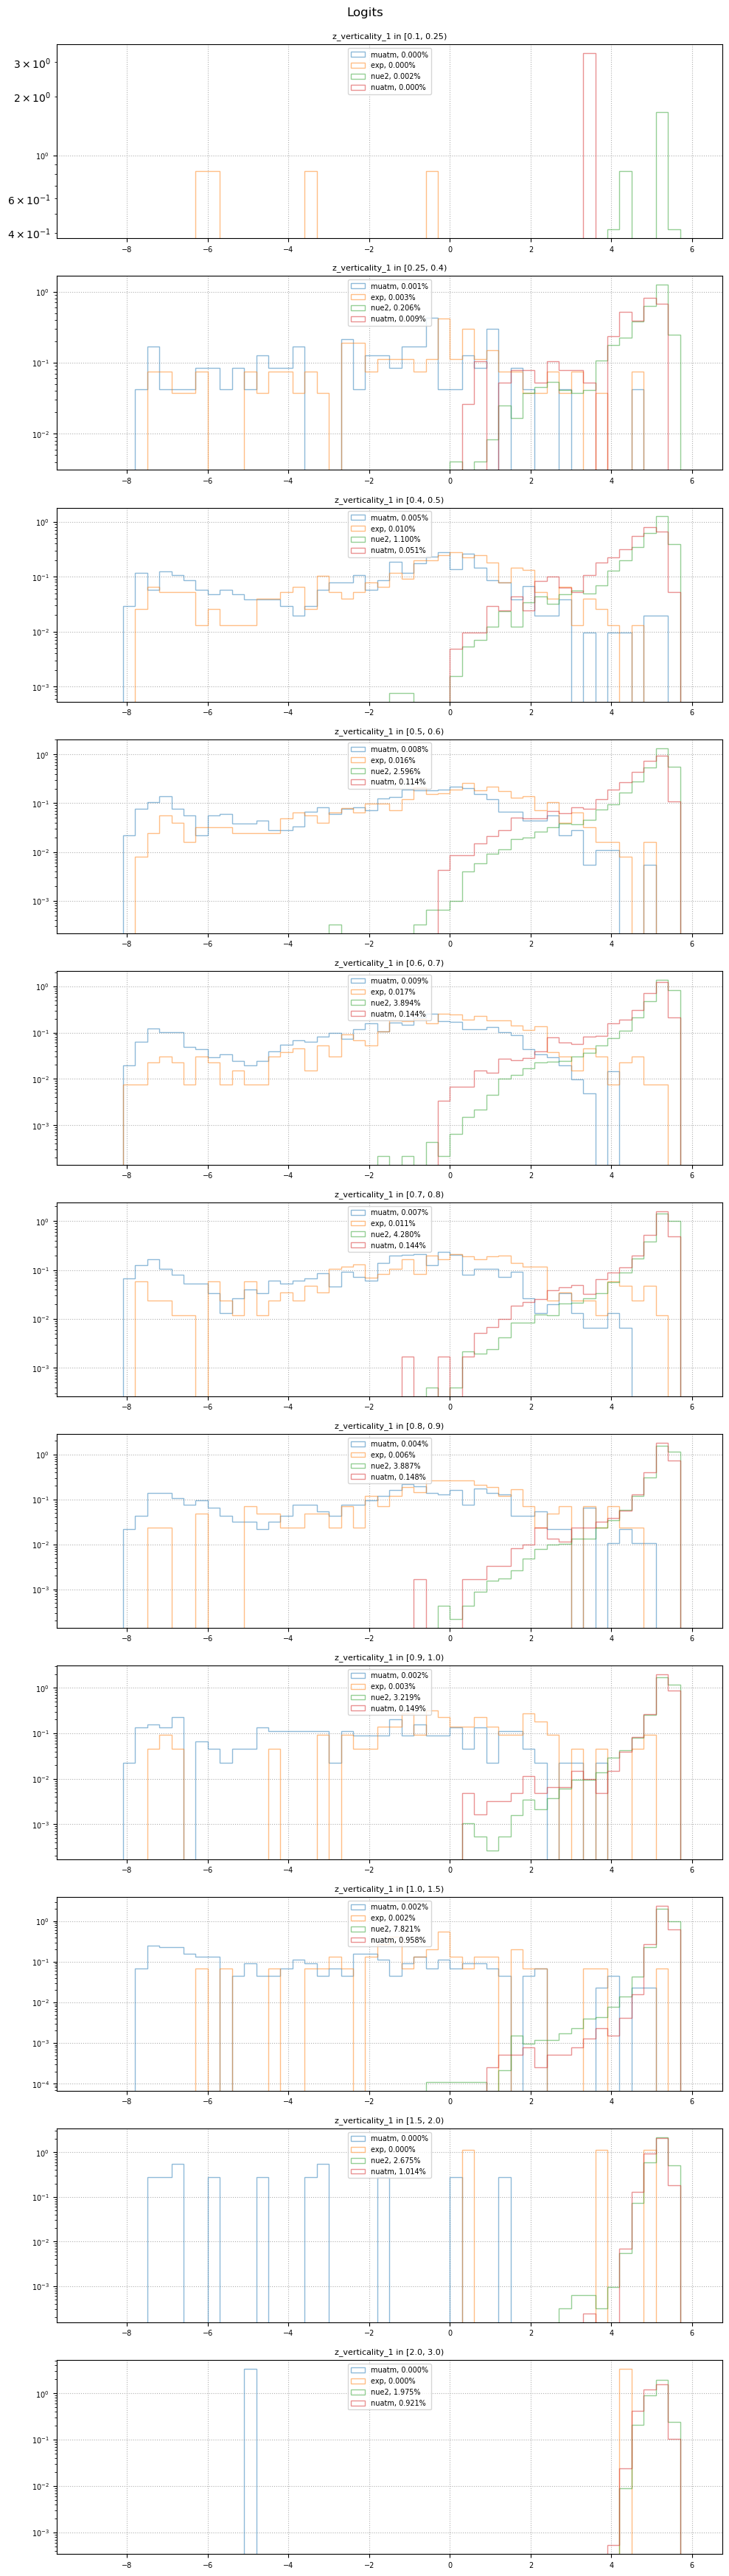

In [197]:
def _apply_mask(df: pd.DataFrame):
    mask = (df.z_t_slope_m_per_ns_q >= 0.1)
    # #mask &= (df.logit>=4)
    # mask = (df.z_verticality_1 >= 1.0)
    # mask &= (df.z_verticality_1 <= 4000)
    #mask &= (df.z_t_residual_rms_m_q <= 10)
    #mask = (df.n_hits < 60)
    #mask = (df.n_hits >= 90) & (df.n_hits <= 100)
    mask &= df.n_sn_hits>=8
    mask &= df.n_sn_strings>=3
    return df[mask].copy()

z_vert_values = [
    (0.1, 0.25),
    (0.25, 0.4), 
    (0.4, 0.5), 
    (0.5, 0.6), 
    (0.6, 0.7), 
    (0.7, 0.8), 
    (0.8, 0.9), 
    (0.9, 1.0), 
    (1.0, 1.5), 
    (1.5, 2.0), 
    (2.0, 3.0)
    ]
MINIMUM_EVENTS = 0                      # below this a density is not worth drawing

colours = {"muatm": "tab:blue", "exp": "tab:orange", "nue2": "tab:green", "nuatm": "tab:red"}

fig, axes = plt.subplots(len(z_vert_values), 1, figsize=(10, 35), sharex=False)

for row, (value_start, value_end) in enumerate(z_vert_values):
    ax = axes[row] if len(z_vert_values) > 1 else axes
    drawn = False
    for name, df in (("muatm", muatm), ("exp", exp), ("nue2", nue2), ("nuatm", nuatm)):
        selected = df[(df.z_verticality_1 >= value_start) & (df.z_verticality_1 < value_end)]
        selected = _apply_mask(selected)
        if len(selected) < MINIMUM_EVENTS:
            continue
        ax.hist(selected.logit, label=f"{name}, {len(selected)/len(df):.3%}", log=True,
                color=colours[name], range=(-9, 6), **hist_kwargs)
        drawn = True
    if not drawn:
        ax.text(0.5, 0.5, f"< {MINIMUM_EVENTS} events", ha="center", va="center",
                transform=ax.transAxes, color="0.5")
        ax.set_yticks([])
    else:
        ax.legend(fontsize=7, loc="upper center")
    ax.tick_params(labelsize=7)
    ax.set_title(f"z_verticality_1 in [{value_start}, {value_end})", fontsize=8)
    ax.grid(ls=":")

fig.suptitle("Logits", y=0.997)
fig.tight_layout()
plt.savefig("figures/logit_by_bright_and_n_hits.png", dpi=300, bbox_inches="tight")
plt.show()


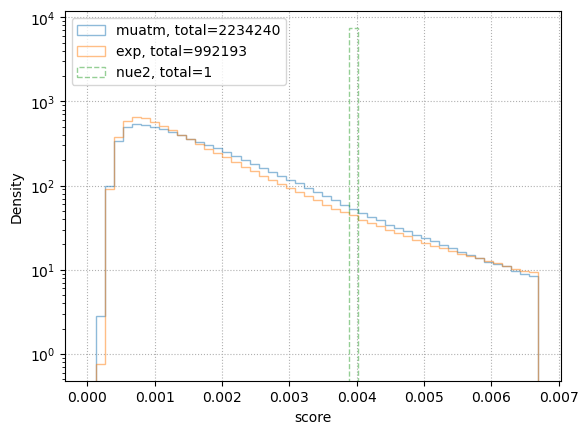

In [88]:
def _apply_mask(df: pd.DataFrame):
    #mask = (df.z_t_slope_m_per_ns >= -0.1)
    mask = (df.logit<=-5)
    #mask &= (df.z_verticality_1 <= 1.0)
    #mask &= (df.z_t_slope_error_m_per_ns <= 0.05)
    #mask = (df.n_hits < 60)
    #mask = (df.n_hits >= 90) & (df.n_hits <= 100)
    mask &= df.n_sn_hits>=8
    mask &= df.n_sn_strings>=3
    return df[mask].copy()

col_to_plot = "score"
_hist_kwargs = dict(density=True, bins=50, alpha=0.5, histtype='step', log=True, range=(0,1/(1+np.exp(5))))
plt.hist(_apply_mask(muatm)[col_to_plot], label=f"muatm, total={len(_apply_mask(muatm))}", **_hist_kwargs)
plt.hist(_apply_mask(exp)[col_to_plot], label=f"exp, total={len(_apply_mask(exp))}", **_hist_kwargs)
plt.hist(_apply_mask(nue2)[col_to_plot], label=f"nue2, total={len(_apply_mask(nue2))}", ls='--', **_hist_kwargs)
plt.xlabel(col_to_plot)
plt.ylabel("Density")
plt.legend()
plt.grid(ls=":")
plt.show()

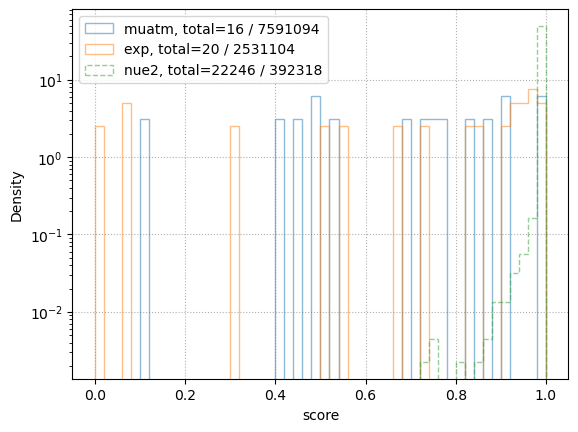

In [109]:
def _apply_mask(df: pd.DataFrame):
    mask = (df.z_t_slope_m_per_ns >= -0.1)
    #mask &= (df.score>=0.5)
    mask &= (df.z_verticality_1 >= 0.5)
    mask &= (df.z_t_residual_rms_m <= 10)
    #mask = (df.n_hits < 60)
    #mask = (df.n_hits >= 90) & (df.n_hits <= 100)
    mask &= df.n_sn_hits>=8
    mask &= df.n_sn_strings>=3
    return df[mask].copy()

col_to_plot = "score"
_hist_kwargs = dict(density=True, bins=50, alpha=0.5, histtype='step', log=True, range=(0., 1))
plt.hist(_apply_mask(muatm)[col_to_plot], label=f"muatm, total={len(_apply_mask(muatm))} / {len(muatm)}", **_hist_kwargs)
plt.hist(_apply_mask(exp)[col_to_plot], label=f"exp, total={len(_apply_mask(exp))} / {len(exp)}", **_hist_kwargs)
plt.hist(_apply_mask(nue2)[col_to_plot], label=f"nue2, total={len(_apply_mask(nue2))} / {len(nue2)}", ls='--', **_hist_kwargs)
plt.xlabel(col_to_plot)
plt.ylabel("Density")
plt.legend()
plt.grid(ls=":")
plt.show()

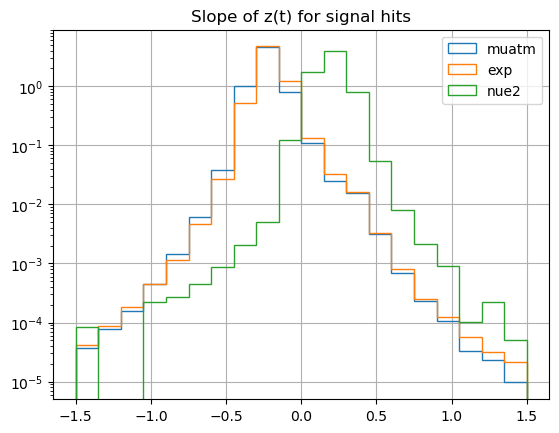

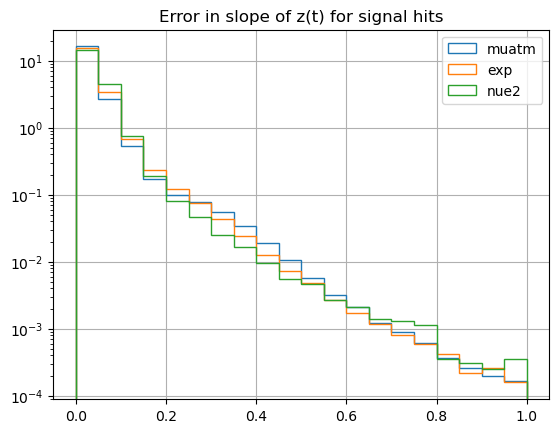

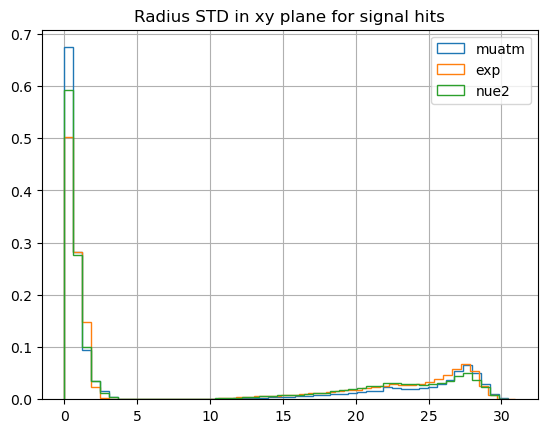

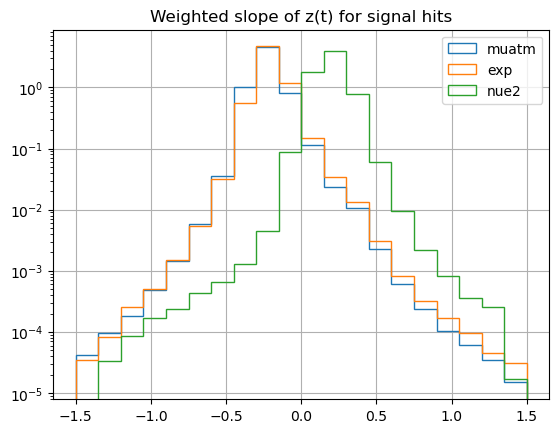

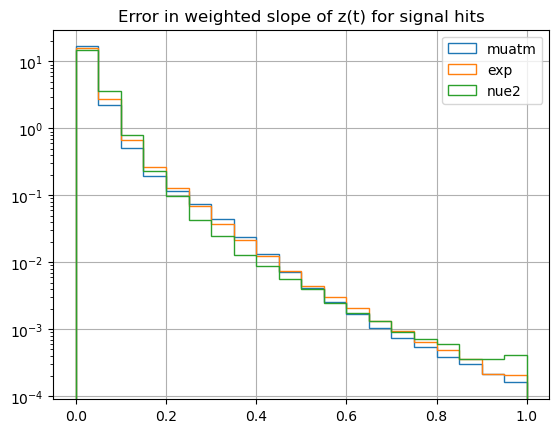

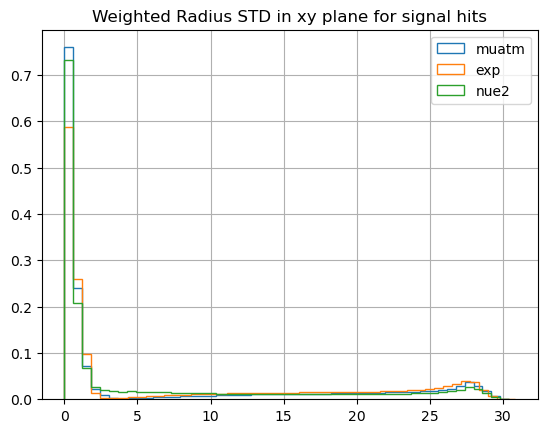

In [74]:
muatm.z_t_slope_m_per_ns.hist(label='muatm', bins=20, histtype='step', density=True, log=True, range=(-1.5,1.5))
exp.z_t_slope_m_per_ns.hist(label='exp', bins=20, histtype='step', density=True, range=(-1.5,1.5))
nue2.z_t_slope_m_per_ns.hist(label='nue2', bins=20, histtype='step', density=True, range=(-1.5,1.5))
plt.title('Slope of z(t) for signal hits')
plt.legend()
plt.show()
muatm.z_t_slope_error_m_per_ns.hist(label='muatm', bins=20, histtype='step', density=True, log=True,  range=(0,1))
exp.z_t_slope_error_m_per_ns.hist(label='exp', bins=20, histtype='step', density=True, range=(0,1))
nue2.z_t_slope_error_m_per_ns.hist(label='nue2', bins=20, histtype='step', density=True, range=(0,1))
plt.title('Error in slope of z(t) for signal hits')
plt.legend()
plt.show()
muatm.sigma_radius_m.hist(label='muatm', bins=50, histtype='step', density=True)
exp.sigma_radius_m.hist(label='exp', bins=50, histtype='step', density=True)
nue2.sigma_radius_m.hist(label='nue2', bins=50, histtype='step', density=True)
plt.title('Radius STD in xy plane for signal hits')
plt.legend()
plt.show()

muatm.z_t_slope_m_per_ns_q.hist(label='muatm', bins=20, histtype='step', density=True, log=True, range=(-1.5,1.5))
exp.z_t_slope_m_per_ns_q.hist(label='exp', bins=20, histtype='step', density=True, range=(-1.5,1.5))
nue2.z_t_slope_m_per_ns_q.hist(label='nue2', bins=20, histtype='step', density=True, range=(-1.5,1.5))
plt.title('Weighted slope of z(t) for signal hits')
plt.legend()
plt.show()
muatm.z_t_slope_error_m_per_ns_q.hist(label='muatm', bins=20, histtype='step', density=True, log=True, range=(0,1))
exp.z_t_slope_error_m_per_ns_q.hist(label='exp', bins=20, histtype='step', density=True, range=(0,1))
nue2.z_t_slope_error_m_per_ns_q.hist(label='nue2', bins=20, histtype='step', density=True, range=(0,1))
plt.title('Error in weighted slope of z(t) for signal hits')
plt.legend()
plt.show()
muatm.sigma_radius_m_q.hist(label='muatm', bins=50, histtype='step', density=True)
exp.sigma_radius_m_q.hist(label='exp', bins=50, histtype='step', density=True)
nue2.sigma_radius_m_q.hist(label='nue2', bins=50, histtype='step', density=True)
plt.title('Weighted Radius STD in xy plane for signal hits')
plt.legend()
plt.show()

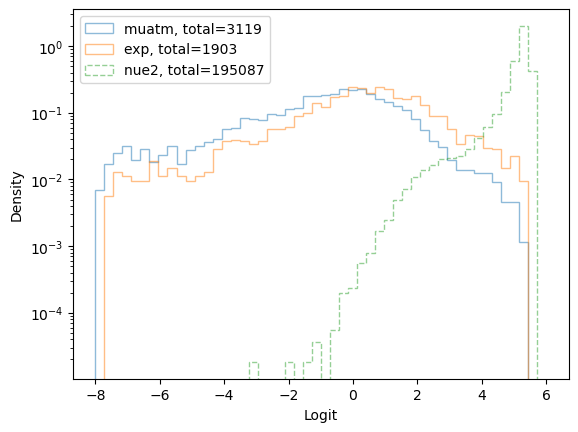

In [ ]:
def _apply_mask(df: pd.DataFrame):
    mask = (df.z_t_slope_m_per_ns >= 0.1)
    mask &= (df.sigma_z_m / df.sigma_horizontal <= 0.5)
    mask &= (df.z_t_slope_error_m_per_ns <= 0.1)
    #mask = (df.n_hits < 60)
    #mask = (df.n_hits >= 90) & (df.n_hits <= 100)
    mask &= df.n_sn_hits>=8
    return df[mask].copy()

plt.hist(_apply_mask(muatm).logit, label=f"muatm, total={len(_apply_mask(muatm))}", log=True, range=(-8, 6), **hist_kwargs)
plt.hist(_apply_mask(exp).logit, label=f"exp, total={len(_apply_mask(exp))}", log=True, range=(-8, 6), **hist_kwargs)
plt.hist(_apply_mask(nue2).logit, label=f"nue2, total={len(_apply_mask(nue2))}", ls='--', log=True, range=(-8, 6), **hist_kwargs)
#plt.hist(_apply_mask(nuatm).score, label=f"nuatm, total={len(_apply_mask(nuatm))}", ls='--', log=True, range=(0, 1), **hist_kwargs)
plt.xlabel("Logit")
plt.ylabel("Density")
plt.legend()
plt.show()

In [68]:
exp_masked = _apply_mask(exp)
exp_masked[exp_masked.score > 0.8]

,source,event_fk,data_class,cluster,run,part_key,local_idx,score,n_sn_hits,n_sn_strings,...,z_t_residual_rms_m,sigma_z_m,sigma_horizontal_m,sigma_radius_m,z_t_slope_m_per_ns_q,z_t_slope_error_m_per_ns_q,z_t_residual_rms_m_q,sigma_z_m_q,sigma_horizontal_m_q,sigma_radius_m_q
76177,exp_full,677314300,exp_full,2,55,part_s2020_c02_r0055,2812320,0.988705,11,4,...,8.338984,21.304981,37.718536,27.474133,0.242617,0.027718,4.466399,13.775626,20.082060,19.390938
393423,exp_full,719616208,exp_full,4,31,part_s2020_c04_r0031,1002569,0.908742,8,3,...,8.457796,21.748594,31.999943,0.908196,0.245317,0.066561,8.233067,14.874203,16.430454,0.420364
556833,exp_full,724454271,exp_full,4,80,part_s2020_c04_r0080,1269752,0.994901,9,3,...,4.744884,63.788391,47.966026,22.507912,0.244650,0.006852,2.869202,38.827724,26.392885,14.572237
570306,exp_full,724793324,exp_full,4,80,part_s2020_c04_r0080,1608805,0.988330,9,2,...,4.081111,22.354700,22.102840,0.911582,0.280046,0.063301,5.697556,11.100810,13.818099,0.598072
857300,exp_full,732482455,exp_full,5,22,part_s2020_c05_r0022,905056,0.994859,8,2,...,8.123844,29.539284,23.275967,0.215602,0.308363,0.021924,5.335814,31.100195,22.834740,0.235084
872154,exp_full,732648699,exp_full,5,22,part_s2020_c05_r0022,1071300,0.977946,8,3,...,21.934011,76.270462,48.537071,18.543821,0.269383,0.024641,11.304296,51.702896,33.882404,6.291955
1177382,exp_full,736331156,exp_full,5,22,part_s2020_c05_r0022,4753757,0.938115,11,2,...,9.826483,28.126263,23.106482,0.187714,0.306011,0.042449,9.614972,25.025370,22.005091,0.189411
1271739,exp_full,742172788,exp_full,5,261,part_s2020_c05_r0261,1498714,0.990615,9,2,...,9.865461,22.406590,26.095940,1.517592,0.132105,0.051595,8.904772,12.391787,24.011141,1.402129
1306498,exp_full,746734159,exp_full,5,337,part_s2020_c05_r0337,948542,0.989892,8,2,...,7.190715,19.764261,23.258867,0.217154,0.218063,0.042195,6.346760,14.818628,20.559963,0.198833
1680305,exp_full,773582394,exp_full,6,481,part_s2020_c06_r0481,156521,0.980571,10,2,...,5.640552,22.743549,26.265434,1.303058,0.240566,0.018935,4.439129,20.427689,25.488852,1.315256


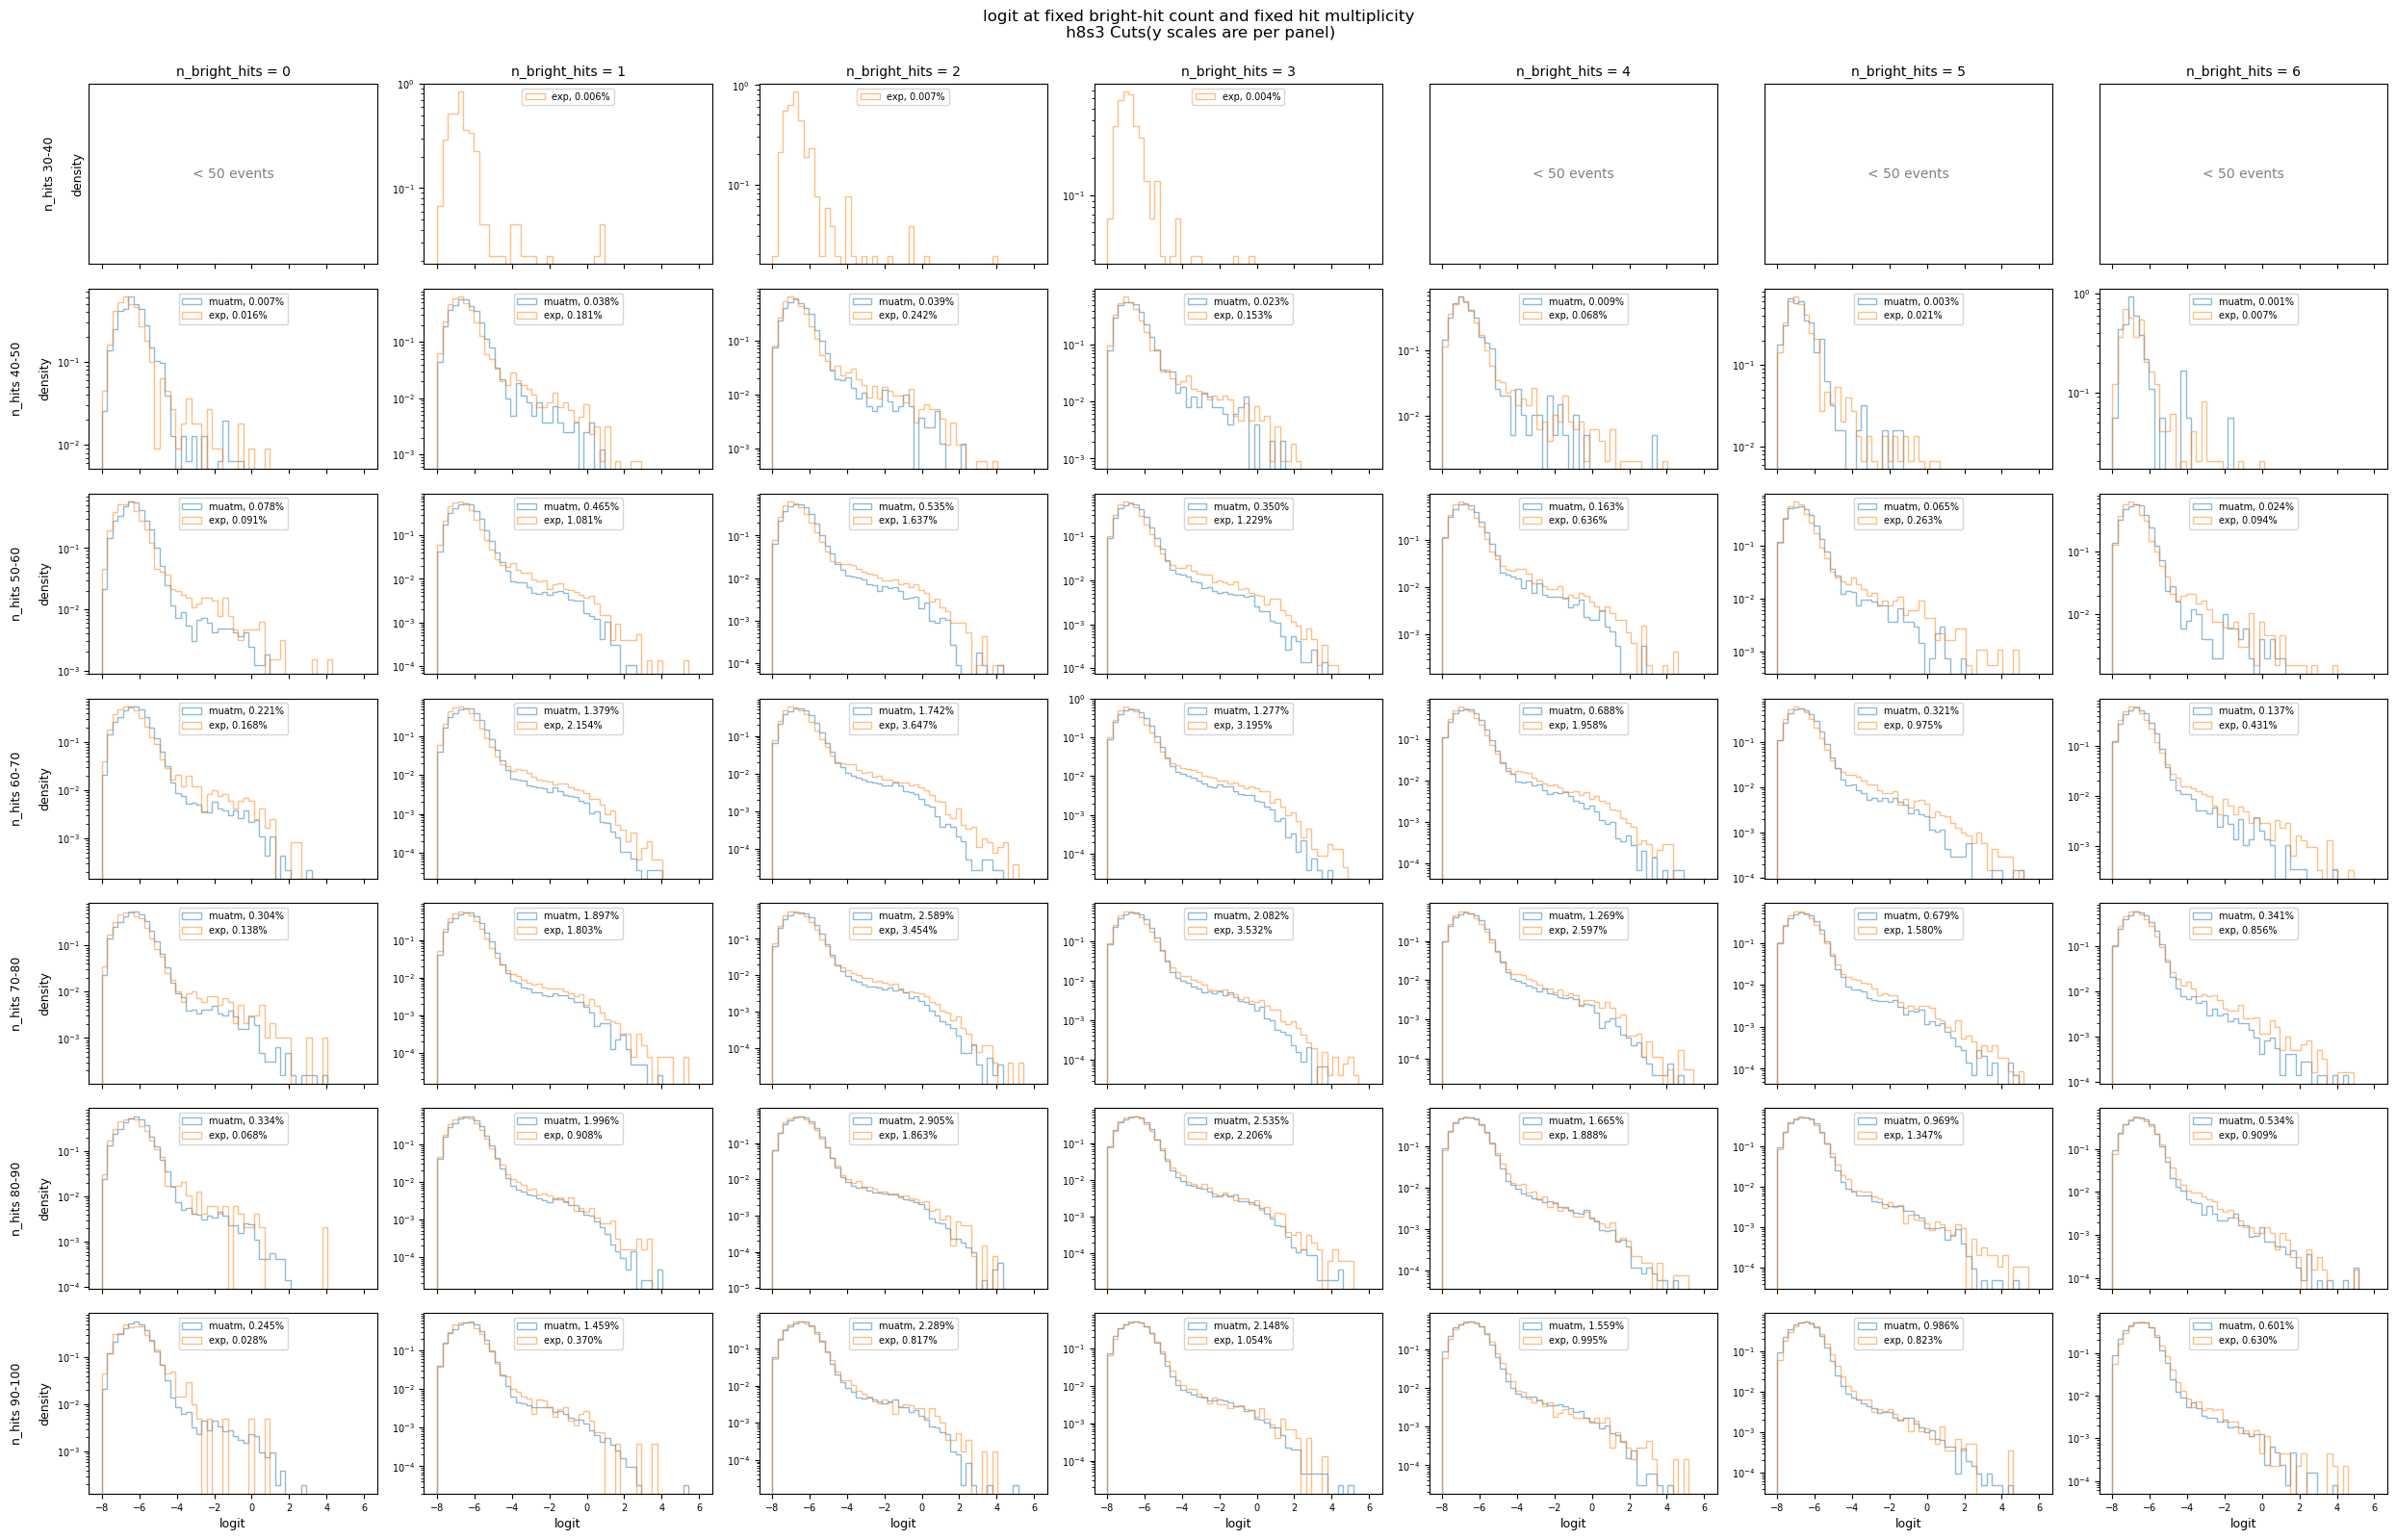

In [55]:
def _apply_mask(df: pd.DataFrame):
    mask = df.n_sn_hits>=8
    return df[mask].copy()

bright_values = range(0, 7)              # n_bright_hits == m
hit_band_starts = list(range(30, 91, 10))      # n_hits in [n, n + 10)
MINIMUM_EVENTS = 50                      # below this a density is not worth drawing

colours = {"muatm": "tab:blue", "exp": "tab:orange"}

fig, axes = plt.subplots(len(hit_band_starts), len(bright_values),
                         figsize=(25, 16), sharex=True)

for row, n in enumerate(hit_band_starts):
    for col, m in enumerate(bright_values):
        ax = axes[row, col]
        drawn = False
        for name, df in (("muatm", muatm), ("exp", exp)):
            selected = df[(df.n_bright_hits == m)
                          & (df.n_hits >= n) & (df.n_hits < n + 10)]
            selected = _apply_mask(selected)
            if len(selected) < MINIMUM_EVENTS:
                continue
            ax.hist(selected.logit, label=f"{name}, {len(selected)/len(df):.3%}", log=True,
                    color=colours[name], range=(-8, 6), **hist_kwargs)
            drawn = True
        if not drawn:
            ax.text(0.5, 0.5, f"< {MINIMUM_EVENTS} events", ha="center", va="center",
                    transform=ax.transAxes, color="0.5")
            ax.set_yticks([])
        else:
            ax.legend(fontsize=7, loc="upper center")
        if row == 0:
            ax.set_title(f"n_bright_hits = {m}", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"n_hits {n}-{n + 10}\n\ndensity", fontsize=9)
        if row == len(hit_band_starts) - 1:
            ax.set_xlabel("logit", fontsize=9)
        ax.tick_params(labelsize=7)

fig.suptitle("logit at fixed bright-hit count and fixed hit multiplicity\n h8s3 Cuts"
             "(y scales are per panel)", y=0.997)
fig.tight_layout()
plt.savefig("figures/logit_by_bright_and_n_hits.png", dpi=300, bbox_inches="tight")
plt.show()


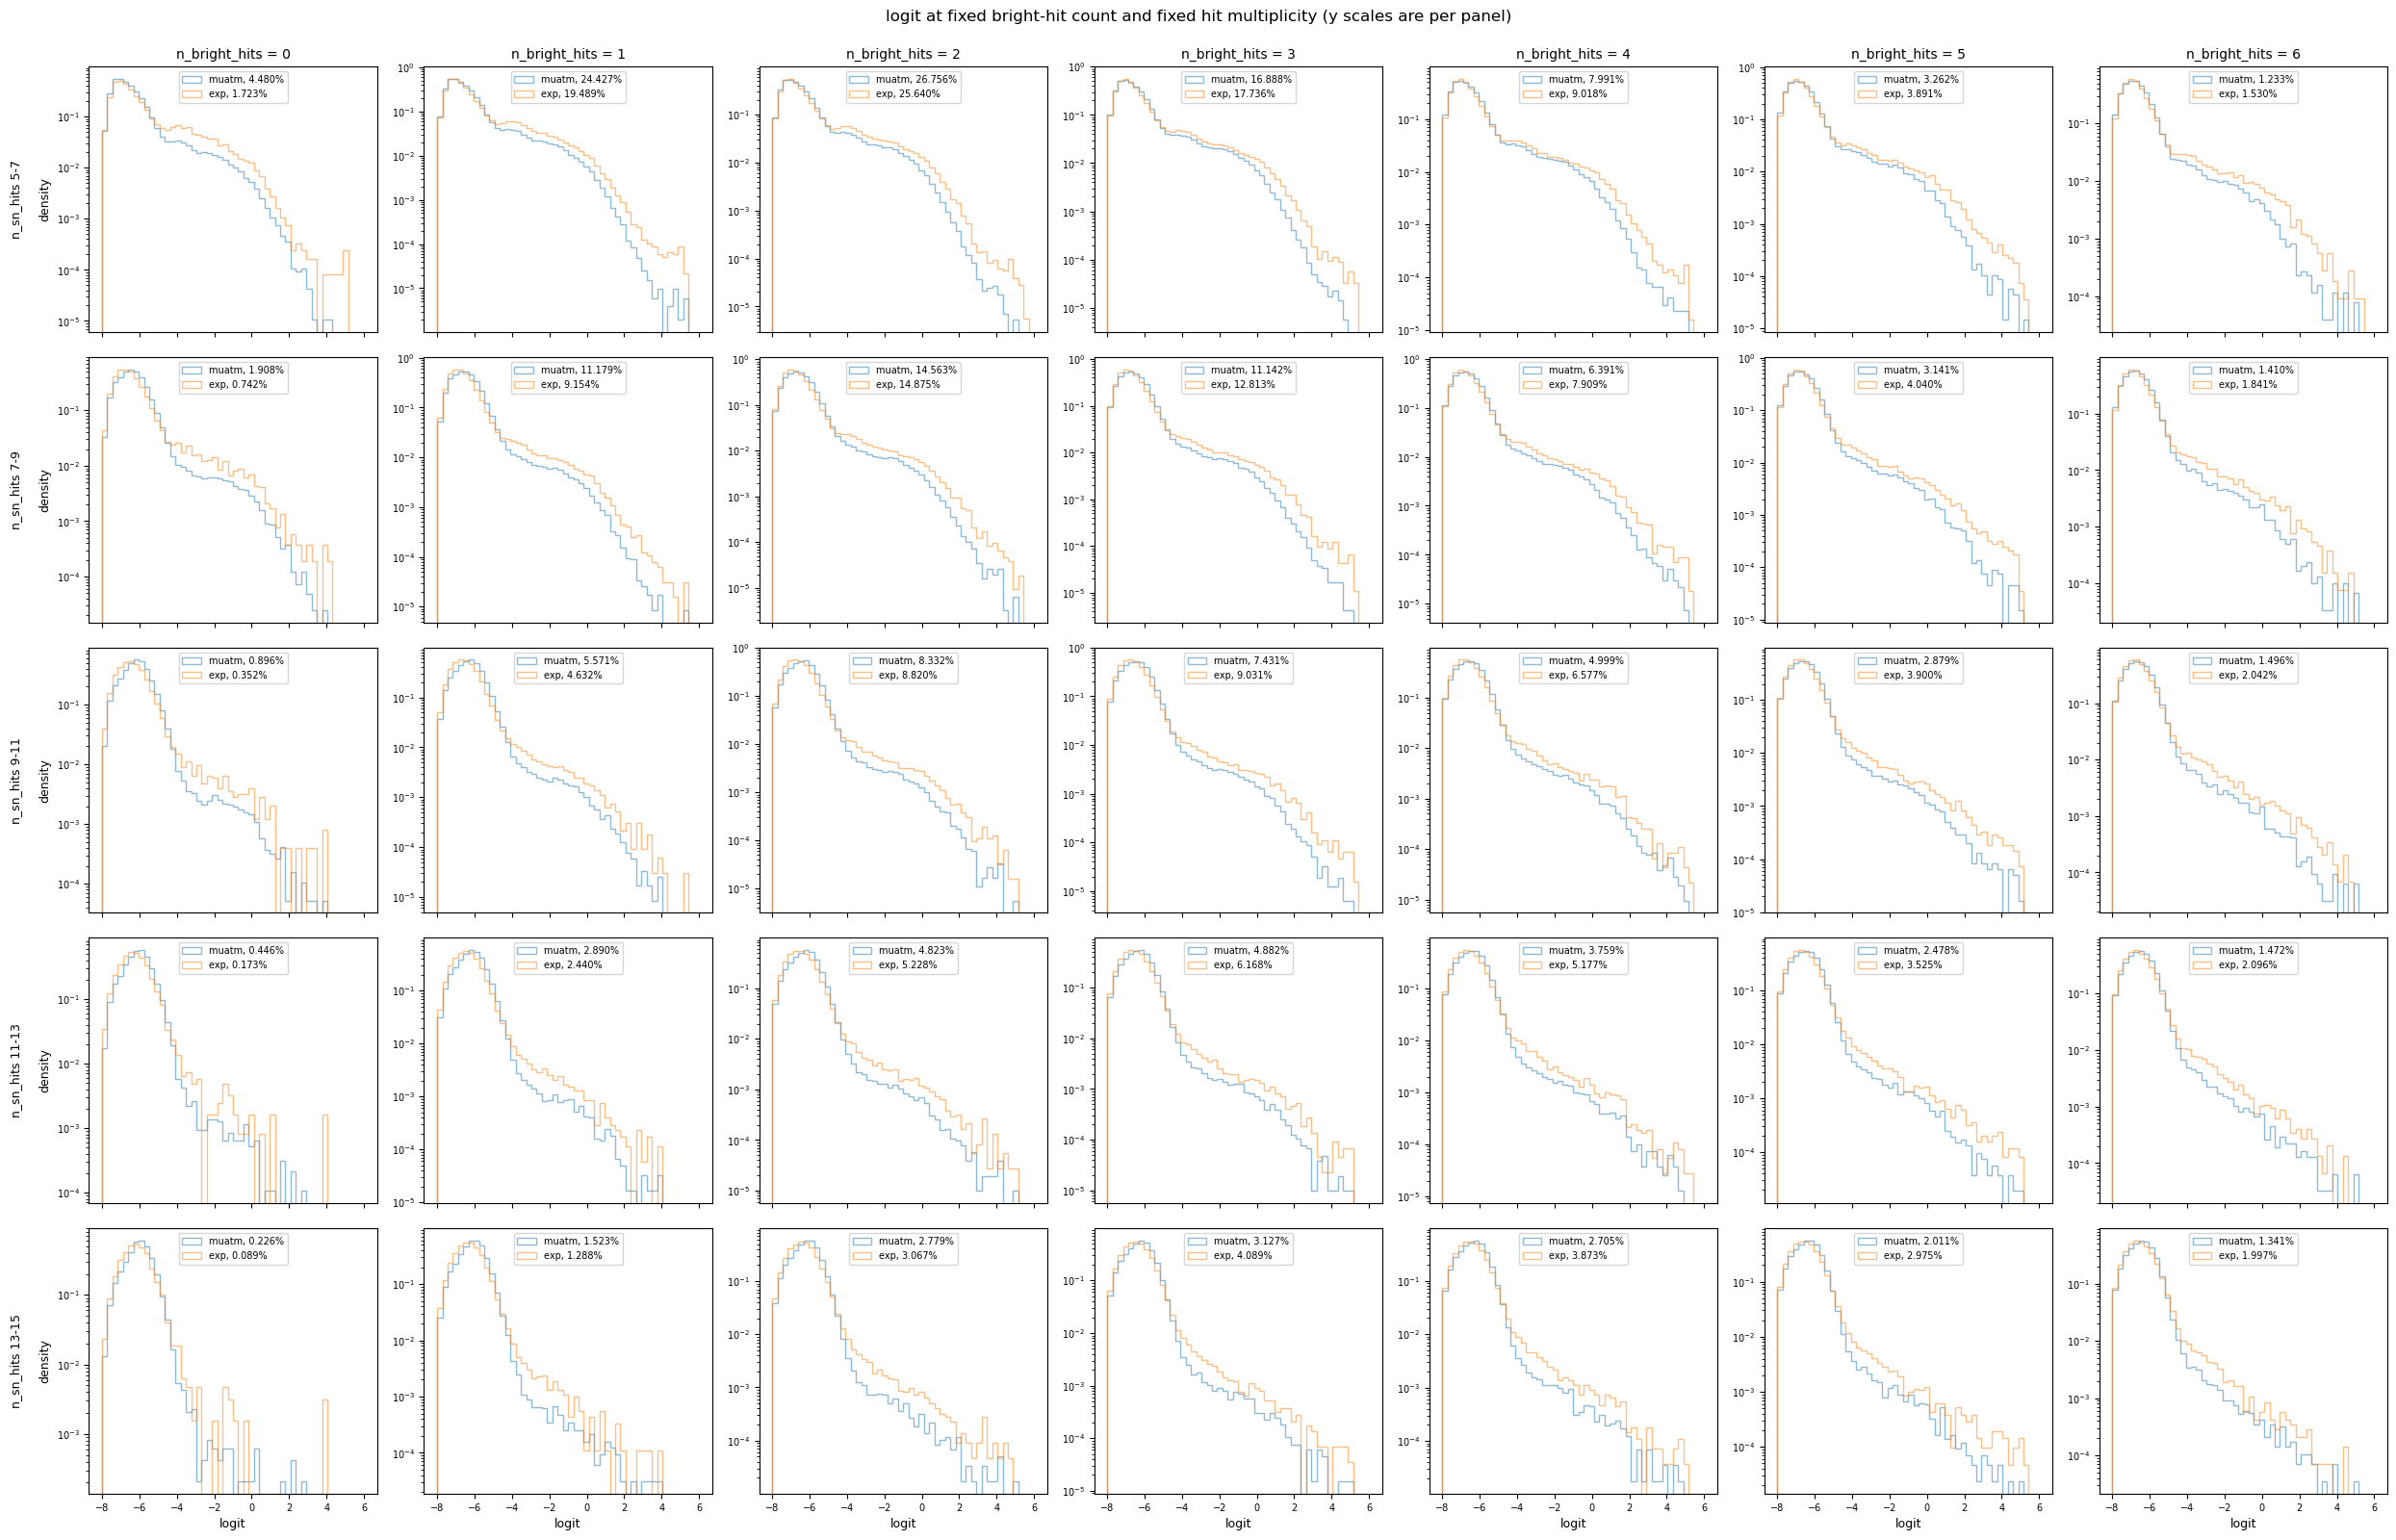

In [56]:
bright_values = range(0, 7)              # n_bright_hits == m
sig_hit_band_starts = list(range(5, 15, 2))      # n_sn_hits in [n, n + 10)
MINIMUM_EVENTS = 50                      # below this a density is not worth drawing

colours = {"muatm": "tab:blue", "exp": "tab:orange"}

fig, axes = plt.subplots(len(sig_hit_band_starts), len(bright_values),
                         figsize=(25, 16), sharex=True)

for row, n in enumerate(sig_hit_band_starts):
    for col, m in enumerate(bright_values):
        ax = axes[row, col]
        drawn = False
        for name, df in (("muatm", muatm), ("exp", exp)):
            selected = df[(df.n_bright_hits == m)
                          & (df.n_sn_hits >= n) & (df.n_sn_hits < n + 10)]
            if len(selected) < MINIMUM_EVENTS:
                continue
            ax.hist(selected.logit, label=f"{name}, {len(selected)/len(df):.3%}", log=True,
                    color=colours[name], range=(-8, 6), **hist_kwargs)
            drawn = True
        if not drawn:
            ax.text(0.5, 0.5, f"< {MINIMUM_EVENTS} events", ha="center", va="center",
                    transform=ax.transAxes, color="0.5")
            ax.set_yticks([])
        else:
            ax.legend(fontsize=7, loc="upper center")
        if row == 0:
            ax.set_title(f"n_bright_hits = {m}", fontsize=10)
        if col == 0:
            ax.set_ylabel(f"n_sn_hits {n}-{n + 2}\n\ndensity", fontsize=9)
        if row == len(sig_hit_band_starts) - 1:
            ax.set_xlabel("logit", fontsize=9)
        ax.tick_params(labelsize=7)

fig.suptitle("logit at fixed bright-hit count and fixed hit multiplicity "
             "(y scales are per panel)", y=0.997)
fig.tight_layout()
plt.savefig("figures/logit_by_bright_and_n_signal_hits.png", dpi=300, bbox_inches="tight")
plt.show()
